In [12]:
import sys
print(sys.executable) 
# !{sys.executable} -m pip install matplotlib_scalebar

/usr/local/bin/python3.11
839.64s - pydevd: Sending message related to process being replaced timed-out after 5 seconds

[notice] A new release of pip is available: 23.1.2 -> 26.2.2
[notice] To update, run: python3.11 -m pip install --upgrade pip


# Atlas Homework
## Atlas of High School Locations (9-12) per North Carolina County


### Data Handling

In [61]:
import io
import zipfile
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib_scalebar.scalebar import ScaleBar

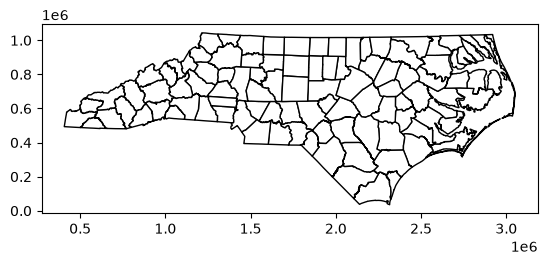

In [62]:
# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level

## Code for county level data 

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].to_crs(6543).copy()
nc_counties = nc_counties.rename(columns={"NAME": "county_name"})
nc_counties = nc_counties.sort_values("county_name")
nc_counties.plot(edgecolor="black", facecolor="white")


# projecting to align with NC tract data
nc_counties = nc_counties.to_crs(epsg=32119)



##### NCES School Data

In [64]:
schools_raw = pd.read_html("NC_Highschools.xls")[0]

# The first 5 rows are NCES notes; row 5 holds the real column names
schools = schools_raw.iloc[6:].copy()
schools.columns = (
    schools_raw.iloc[5]
    .astype(str)
    .str.replace("\xa0", " ")
    .str.strip()
)
schools = schools.reset_index(drop=True)
schools["NCES School ID"] = schools["NCES School ID"].astype(str)

schools.head()

5,NCES School ID,State School ID,NCES District ID,State District ID,Low Grade,High Grade,School Name,District,County Name*,Street Address,...,Locale*,Charter,Students*,Teachers*,Student Teacher Ratio*,Free Lunch*,Reduced Lunch*,Directly Certified*,Type,Status
0,370243001039,NC-132-304,3702430,NC-132,09,12,A L Brown High,Kannapolis City Schools,Cabarrus County,415 Martin Luther King Jr Ave,...,"Suburban, Large",No,1753.00000,93.98000,18.6500000,1750.00000,0.00000,–,Regular,Open
1,370192002669,NC-410-483,3701920,NC-410,09,12,A&T Four Middle College,Guilford County Schools,Guilford County,1601 East Market Street,...,"City, Large",No,162.00000,13.58000,11.9300000,159.00000,0.00000,–,Regular,Open
2,370003002972,NC-010-303,3700030,NC-010,09,12,ABSS Early College at ACC,Alamance-Burlington Schools,Alamance County,PO Box 8000,...,"Suburban, Midsize",No,247.00000,8.25000,29.9400000,78.00000,12.00000,–,Regular,Open
3,370192002889,NC-410-545,3701920,NC-410,09,12,Academy at Smith,Guilford County Schools,Guilford County,2225 South Holden Road,...,"City, Large",No,246.00000,19.74000,12.4600000,243.00000,0.00000,–,Regular,Open
4,370432000022,NC-840-302,3704320,NC-840,09,12,Albemarle High,Stanly County Schools,Stanly County,311 Park Ridge Road,...,"Town, Distant",No,414.00000,30.46000,13.5900000,410.00000,0.00000,–,Regular,Open


##### Building Geodata Frame

In [65]:
edge_url = "https://nces.ed.gov/programs/edge/data/EDGE_GEOCODE_PUBLICSCH_2425.zip"
r = requests.get(edge_url)
z = zipfile.ZipFile(io.BytesIO(r.content))

# (columns 0, 12, 13 of this file are school ID, latitude, longitude)
edge = pd.read_csv(
    z.open("EDGE_GEOCODE_PUBLICSCH_2425.TXT"),
    sep="|", header=None, usecols=[0, 12, 13],
    names=["NCESSCH", "LAT", "LON"],
    dtype={"NCESSCH": str}, encoding="latin-1"
)

schools = schools.merge(edge, left_on="NCES School ID", right_on="NCESSCH", how="left")

schools_gdf = gpd.GeoDataFrame(
    schools,
    geometry=gpd.points_from_xy(schools["LON"], schools["LAT"]),
    crs="EPSG:4269"
).to_crs(epsg=32119)

print(schools_gdf["LAT"].isna().sum(), "schools without coordinates")

0 schools without coordinates


### Spatial Join

In [66]:

joined = gpd.sjoin(
    schools_gdf,
    nc_counties[["county_name", "geometry"]],
    how="inner",
    predicate="within"
)

counts = joined.groupby("county_name").size()
nc_counties["school_count"] = nc_counties["county_name"].map(counts).fillna(0).astype(int)

print("School Name" in joined.columns)
nc_counties[["county_name", "school_count"]].head(10)


True


,county_name,school_count
1930,Alamance,9
2242,Alexander,2
2612,Alleghany,1
344,Anson,1
93,Ashe,1
2132,Avery,1
1175,Beaufort,3
593,Bertie,1
1294,Bladen,2
699,Brunswick,3


## Making the Atlas

In [ ]:
atlas_counties = ["Burke", "Catawba"]

with PdfPages("nc_county_atlas.pdf") as pdf:
    for index, row in nc_counties[nc_counties["county_name"].isin(atlas_counties)].iterrows():        
        name = row["county_name"]
        count = row["school_count"]
        county = nc_counties.loc[nc_counties["county_name"] == name]
        county_schools = joined[joined["county_name"] == name]

        # phrase built with concatenation
        if count == 1:
            phrase = "There is 1 public high school in " + name + " County."
        else:
            phrase = "There are " + str(count) + " public high schools in " + name + " County."

        fig = plt.figure(figsize=(8.5, 11))

        # primary map
        ax = fig.add_axes([0.05, 0.28, 0.9, 0.62])
        nc_counties.plot(ax=ax, facecolor="#eeeeee", edgecolor="white")
        county.plot(ax=ax, facecolor="#7b9b90", edgecolor="black")
        if count > 0:
            county_schools.plot(ax=ax, color="#13294B", markersize=20)
        for i, s in county_schools.iterrows():
            ax.text(s.geometry.x, s.geometry.y + 800, s["School Name"],
                    fontsize=5, ha="center", va="bottom")

        # padding and zoom 
        minx, miny, maxx, maxy = row.geometry.bounds
        pad = 0.2 * max(maxx - minx, maxy - miny)
        ax.set_xlim(minx - pad, maxx + pad)
        ax.set_ylim(miny - pad, maxy + pad)
        ax.add_artist(ScaleBar(1, location="lower left"))
        ax.set_axis_off()

        # title
        fig.text(0.5, 0.94, name + " County", ha="center", fontsize=24, weight="bold")
        fig.text(0.05, 0.22, phrase, fontsize=14)

        # locator map
        loc_ax = fig.add_axes([0.55, 0.03, 0.4, 0.17])
        nc_counties.plot(ax=loc_ax, facecolor="white", edgecolor="gray")
        county.plot(ax=loc_ax, facecolor="#7b9b90", edgecolor="black")
        loc_ax.set_axis_off()

        pdf.savefig(fig)
        plt.close(fig)

print("Atlas is created and saved to nc_county_atlas.pdf")

Atlas is created and saved to nc_county_atlas.pdf
